# Top-view image

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import itertools
import numpy as np
import math

In [2]:
DATA_DIR = Path("./../data")
# IMAGE_PATH = DATA_DIR / "development_set/3f_png.rf.81c7e132365ef95bb19380ca389025f6.jpg"
IMAGE_PATH = DATA_DIR / "development_set/4a_png.rf.a6bb5c5706fd8628eb53d34a122cf441.jpg"

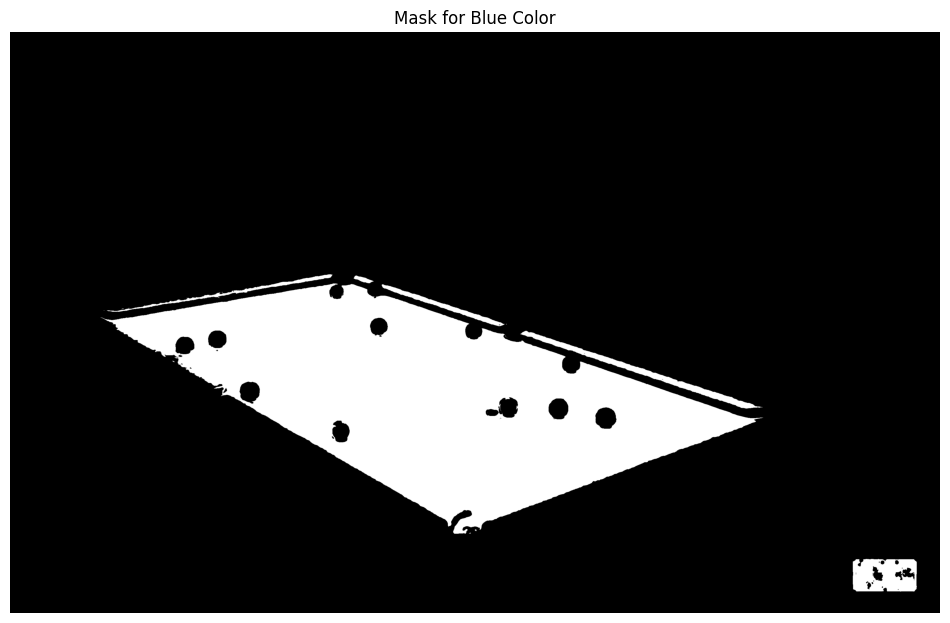

In [3]:
image = cv2.imread(str(IMAGE_PATH))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply Gaussian
image = cv2.GaussianBlur(image, (15, 15), 0)

# Mask Blue cloth
hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

lower_blue = np.array([200/2, 60 / 100 * 255, 60 / 100 * 255])
upper_blue = np.array([210/2, 110 / 100 * 255, 110 / 100 * 255])

mask_table = cv2.inRange(hsv_image, lower_blue, upper_blue)

plt.figure(figsize=(12, 8))
plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title('Mask for Blue Color')
plt.show()

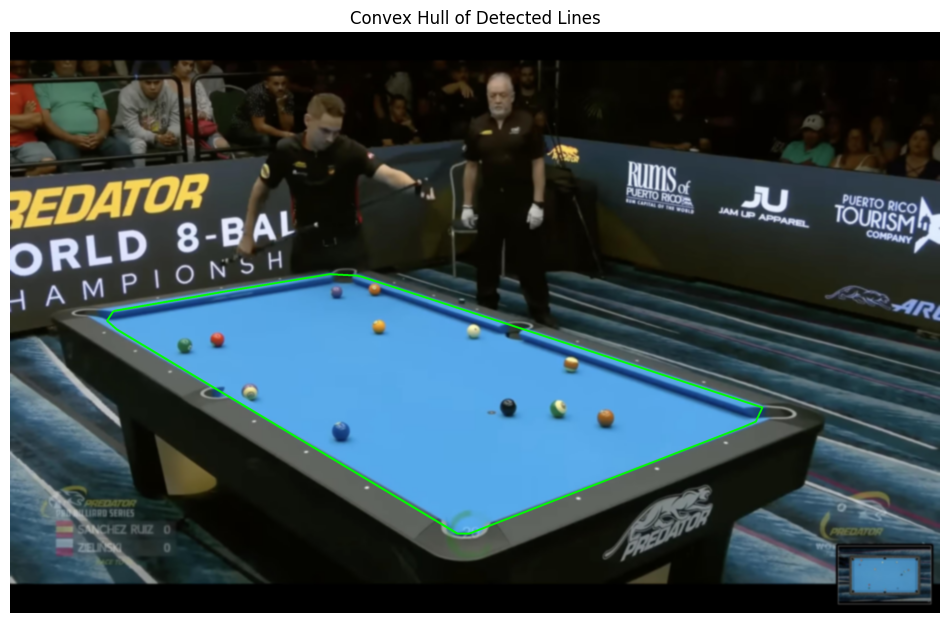

In [4]:
edges = cv2.Canny(mask_table, 50, 150)

lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold=80,
    minLineLength=100,
    maxLineGap=80
)

tmp_lines = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    if length >= 250:
        tmp_lines.append(line)
lines = tmp_lines

pts = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    pts.append((x1, y1))
    pts.append((x2, y2))

pts = np.array(pts)
hull = cv2.convexHull(pts)

line_image = image.copy()
cv2.polylines(line_image, [hull], isClosed=True, color=(0, 255, 0), thickness=5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Convex Hull of Detected Lines')
plt.show()

14


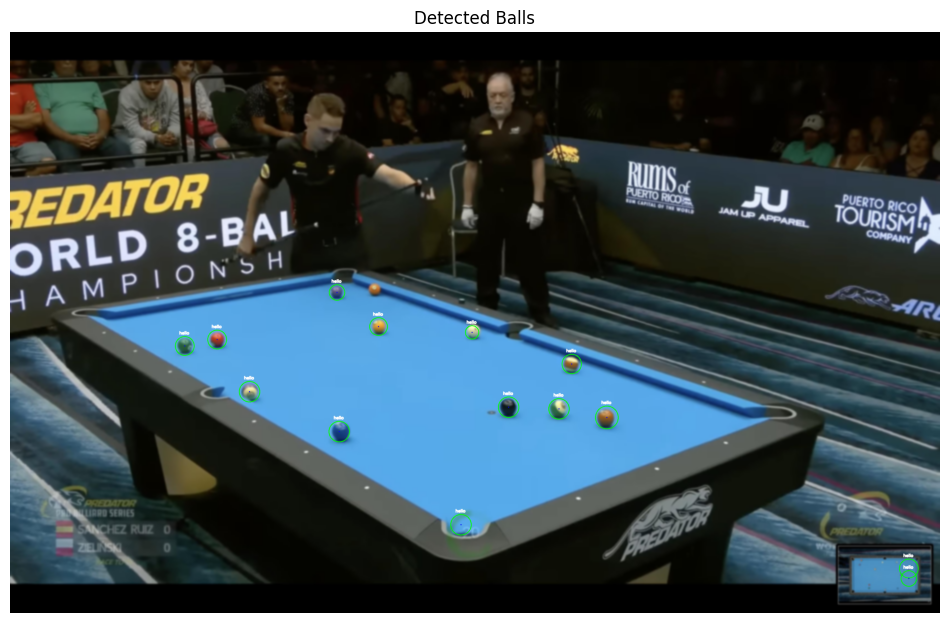

In [5]:
balls_image = image.copy()

circles = cv2.HoughCircles(
    mask_table,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=18,       # tune based on ball spacing
    param1=100,       # Canny upper threshold
    param2=18,        # smaller -> more detections, larger -> fewer
    minRadius=20,      # tune to your image scale
    maxRadius=50
)

circles = np.round(circles[0]).astype(int)
print(len(circles))

for (x, y, r) in circles:
    cv2.circle(balls_image, (x, y), r, (0, 255, 0), 2)
    cv2.circle(balls_image, (x, y), 2, (0, 0, 255), -1)
    cv2.putText(
        balls_image, "hello", (x - 20, y - r - 8),
        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2, cv2.LINE_AA
    )

plt.figure(figsize=(12, 8))
plt.imshow(balls_image)
plt.axis('off')
plt.title('Detected Balls')
plt.show()